Dataset loaded successfully
Rows and Columns: (1000, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   title      1000 non-null   object 
 1   magnitude  1000 non-null   float64
 2   date_time  1000 non-null   object 
 3   cdi        1000 non-null   int64  
 4   mmi        1000 non-null   int64  
 5   alert      449 non-null    object 
 6   tsunami    1000 non-null   int64  
 7   sig        1000 non-null   int64  
 8   net        1000 non-null   object 
 9   nst        1000 non-null   int64  
 10  dmin       1000 non-null   float64
 11  gap        1000 non-null   float64
 12  magType    1000 non-null   object 
 13  depth      1000 non-null   float64
 14  latitude   1000 non-null   float64
 15  longitude  1000 non-null   float64
 16  location   994 non-null    object 
 17  continent  284 non-null    object 
 18  country    651 non-null    objec

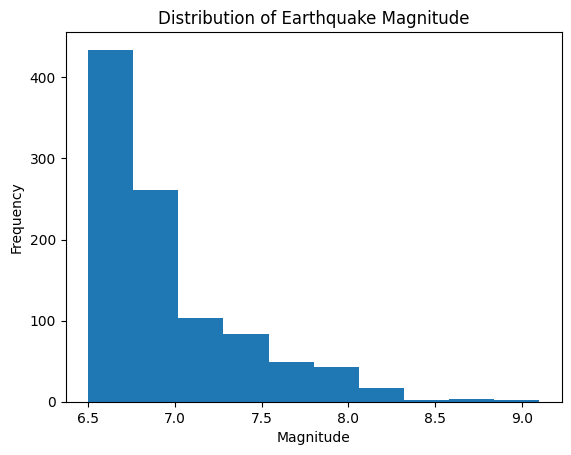

Magnitude skewness: 1.3665595466049707


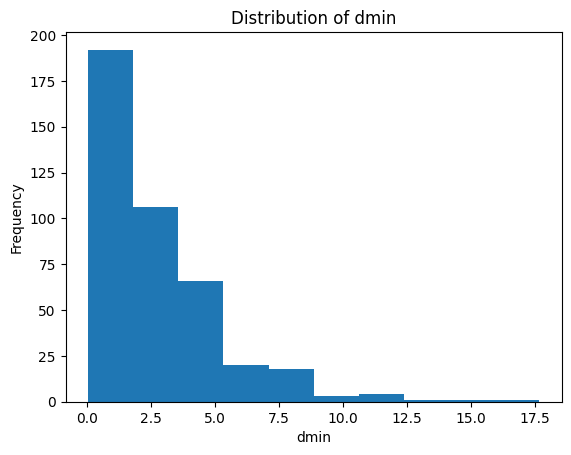

dmin skewness: 1.9997583308140012
Magnitude
Mean: 6.940831663326654
Median: 6.8

dmin
Mean: 2.7310060048543687
Median: 1.9915
Magnitude
Mean: 6.940831663326654
Median: 6.8

dmin
Mean: 2.7310060048543687
Median: 1.9915


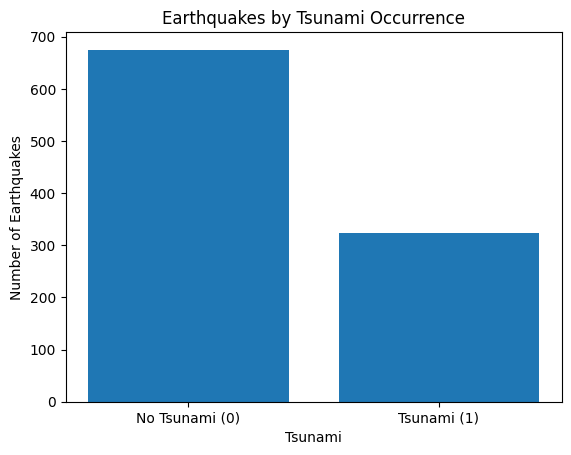

Missing values after cleaning:
title          0
magnitude      0
date_time      0
cdi            0
mmi            0
alert        549
tsunami        0
sig            0
net            0
nst            0
dmin           0
gap            0
magType        0
depth          0
latitude       0
longitude      0
location       0
continent      0
country        0
dtype: int64
Total missing values: 549
Cleaned dataset saved successfully


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("earthquake_1995-2023.csv")

print("Dataset loaded successfully")

print("Rows and Columns:", df.shape)

df.info()
exact_duplicates = df.duplicated().sum()

print("Fully identical duplicate rows:", exact_duplicates)
key_duplicates = df.duplicated(
    subset=["title", "date_time"]
).sum()

print("Duplicate earthquakes using title + date_time:", key_duplicates)
rows_before = len(df)

print("Rows before removing duplicates:", rows_before)
df = df.drop_duplicates()

df = df.drop_duplicates(
    subset=["title", "date_time"]
)

print("Duplicates removed successfully")

rows_after = len(df)

print("Rows after removing duplicates:", rows_after)
print("Total rows removed:", rows_before - rows_after)

missing_count = df.isnull().sum()

print("Missing values in each column:")
print(missing_count)

missing_percent = df.isnull().mean() * 100

missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent
})

missing_report

zero_columns = ["cdi", "gap", "nst", "dmin"]

for col in zero_columns:
    print(col, "zero values:", (df[col] == 0).sum())
    zero_columns = ["cdi", "gap", "nst", "dmin"]

for col in zero_columns:
    print(col, "zero values:", (df[col] == 0).sum())



for col in zero_columns:
    df[col] = df[col].replace(0, np.nan)

print("Zero placeholders converted to NaN")

print(df.isnull().sum())

plt.hist(df["magnitude"].dropna(), bins=10)

plt.title("Distribution of Earthquake Magnitude")
plt.xlabel("Magnitude")
plt.ylabel("Frequency")

plt.show()
magnitude_skew = df["magnitude"].skew()

print("Magnitude skewness:", magnitude_skew)

plt.hist(df["dmin"].dropna(), bins=10)

plt.title("Distribution of dmin")
plt.xlabel("dmin")
plt.ylabel("Frequency")

plt.show()
dmin_skew = df["dmin"].skew()

print("dmin skewness:", dmin_skew)

print("Magnitude")
print("Mean:", df["magnitude"].mean())
print("Median:", df["magnitude"].median())

print("\ndmin")
print("Mean:", df["dmin"].mean())
print("Median:", df["dmin"].median())

print("Magnitude")
print("Mean:", df["magnitude"].mean())
print("Median:", df["magnitude"].median())

print("\ndmin")
print("Mean:", df["dmin"].mean())
print("Median:", df["dmin"].median())


df["dmin"] = df["dmin"].fillna(df["dmin"].median())

for col in ["cdi", "gap", "nst"]:
    df[col] = df[col].fillna(df[col].median())
for col in ["location", "continent", "country"]:
    df[col] = df[col].fillna("Unknown")

    tsunami_counts = df["tsunami"].value_counts().sort_index()

plt.bar(
    ["No Tsunami (0)", "Tsunami (1)"],
    [
        tsunami_counts.get(0, 0),
        tsunami_counts.get(1, 0)
    ]
)

plt.title("Earthquakes by Tsunami Occurrence")
plt.xlabel("Tsunami")
plt.ylabel("Number of Earthquakes")

plt.show()

print("Missing values after cleaning:")
print(df.isnull().sum())

total_missing = df.isnull().sum().sum()

print("Total missing values:", total_missing)

df.to_csv("earthquake_cleaned.csv", index=False)

print("Cleaned dataset saved successfully")